In [1]:
import os

# Check the dataset file
print(os.listdir("../data"))

['googleplaystore.csv']


In [2]:
# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# Load Google Play Store dataset into a DataFrame
data = pd.read_csv("../data/googleplaystore.csv")

# Display the first five rows
data.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [4]:
# Display the number of rows and columns
print("Dataset Shape:", data.shape)

# Display column names
print("\nColumn Names:")
print(data.columns.tolist())

Dataset Shape: (10841, 13)

Column Names:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']


In [5]:
# Display dataset information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [6]:
# Count missing values in every column
data.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

In [7]:
# Count duplicate rows
print("Duplicate rows:", data.duplicated().sum())

Duplicate rows: 483


In [8]:
# Calculate missing values in each column
missing_values = data.isnull().sum()

# Calculate missing percentage
missing_percentage = (missing_values / len(data)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

# Display columns having missing values
missing_summary[missing_summary["Missing Values"] > 0]

,Missing Values,Missing Percentage
Rating,1474,13.596532
Type,1,0.009224
Content Rating,1,0.009224
Current Ver,8,0.073794
Android Ver,3,0.027673


In [9]:
# Count duplicate application names
print("Duplicate App Names:", data["App"].duplicated().sum())

# Display applications with repeated names
data[data["App"].duplicated(keep=False)].sort_values("App").head(10)

Duplicate App Names: 1181


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
1393,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,3.8M,"500,000+",Free,0,Everyone 10+,Health & Fitness,"February 17, 2017",1.9,2.3.3 and up
1407,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,3.8M,"500,000+",Free,0,Everyone 10+,Health & Fitness,"February 17, 2017",1.9,2.3.3 and up
2543,1800 Contacts - Lens Store,MEDICAL,4.7,23160,26M,"1,000,000+",Free,0,Everyone,Medical,"July 27, 2018",7.4.1,5.0 and up
2322,1800 Contacts - Lens Store,MEDICAL,4.7,23160,26M,"1,000,000+",Free,0,Everyone,Medical,"July 27, 2018",7.4.1,5.0 and up
2385,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,3.8M,"1,000+",Paid,$16.99,Everyone,Medical,"January 27, 2017",1.0.5,4.0.3 and up
2256,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,3.8M,"1,000+",Paid,$16.99,Everyone,Medical,"January 27, 2017",1.0.5,4.0.3 and up
1337,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,15M,"100,000+",Free,0,Everyone,Health & Fitness,"August 2, 2018",3.0.0,4.1 and up
1434,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,15M,"100,000+",Free,0,Everyone,Health & Fitness,"August 2, 2018",3.0.0,4.1 and up
3083,365Scores - Live Scores,SPORTS,4.6,666521,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up
5415,365Scores - Live Scores,SPORTS,4.6,666246,25M,"10,000,000+",Free,0,Everyone,Sports,"July 29, 2018",5.5.9,4.1 and up


In [10]:
# Display records where Rating is missing
data[data["Rating"].isnull()].head(10)

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
23,Mcqueen Coloring pages,ART_AND_DESIGN,NaN,61,7.0M,"100,000+",Free,0,Everyone,Art & Design;Action & Adventure,"March 7, 2018",1.0.0,4.1 and up
113,Wrinkles and rejuvenation,BEAUTY,NaN,182,5.7M,"100,000+",Free,0,Everyone 10+,Beauty,"September 20, 2017",8.0,3.0 and up
123,Manicure - nail design,BEAUTY,NaN,119,3.7M,"50,000+",Free,0,Everyone,Beauty,"July 23, 2018",1.3,4.1 and up
126,Skin Care and Natural Beauty,BEAUTY,NaN,654,7.4M,"100,000+",Free,0,Teen,Beauty,"July 17, 2018",1.15,4.1 and up
129,"Secrets of beauty, youth and health",BEAUTY,NaN,77,2.9M,"10,000+",Free,0,Mature 17+,Beauty,"August 8, 2017",2.0,2.3 and up
130,Recipes and tips for losing weight,BEAUTY,NaN,35,3.1M,"10,000+",Free,0,Everyone 10+,Beauty,"December 11, 2017",2.0,3.0 and up
134,"Lady adviser (beauty, health)",BEAUTY,NaN,30,9.9M,"10,000+",Free,0,Mature 17+,Beauty,"January 24, 2018",3.0,3.0 and up
163,Anonymous caller detection,BOOKS_AND_REFERENCE,NaN,161,2.7M,"10,000+",Free,0,Everyone,Books & Reference,"July 13, 2018",1.0,2.3 and up
180,SH-02J Owner's Manual (Android 8.0),BOOKS_AND_REFERENCE,NaN,2,7.2M,"50,000+",Free,0,Everyone,Books & Reference,"June 15, 2018",3.0,6.0 and up
185,URBANO V 02 instruction manual,BOOKS_AND_REFERENCE,NaN,114,7.3M,"100,000+",Free,0,Everyone,Books & Reference,"August 7, 2015",1.1,5.1 and up


In [11]:
# Find applications with duplicate names
duplicate_apps = data[data["App"].duplicated(keep=False)]

# Sort by application name
duplicate_apps = duplicate_apps.sort_values("App")

# Display first 20 records
duplicate_apps[["App", "Category", "Rating", "Reviews", "Installs"]].head(20)

,App,Category,Rating,Reviews,Installs
1393,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,"500,000+"
1407,10 Best Foods for You,HEALTH_AND_FITNESS,4.0,2490,"500,000+"
2543,1800 Contacts - Lens Store,MEDICAL,4.7,23160,"1,000,000+"
2322,1800 Contacts - Lens Store,MEDICAL,4.7,23160,"1,000,000+"
2385,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,"1,000+"
2256,2017 EMRA Antibiotic Guide,MEDICAL,4.4,12,"1,000+"
1337,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,"100,000+"
1434,21-Day Meditation Experience,HEALTH_AND_FITNESS,4.4,11506,"100,000+"
3083,365Scores - Live Scores,SPORTS,4.6,666521,"10,000,000+"
5415,365Scores - Live Scores,SPORTS,4.6,666246,"10,000,000+"


In [12]:
# Count unique application names
print("Total unique apps:", data["App"].nunique())

# Count duplicate application names
print("Duplicate app-name rows:", data["App"].duplicated().sum())

Total unique apps: 9660
Duplicate app-name rows: 1181


In [13]:
# Create a separate copy of the original dataset
df = data.copy()

# Remove exact duplicate rows
df = df.drop_duplicates()

# Check the new dataset shape
print("Original dataset:", data.shape)
print("After removing duplicates:", df.shape)

# Check remaining exact duplicates
print("Remaining duplicates:", df.duplicated().sum())

Original dataset: (10841, 13)
After removing duplicates: (10358, 13)
Remaining duplicates: 0


In [14]:
# Find applications having multiple records
app_counts = df["App"].value_counts()

# Display applications appearing more than once
repeated_apps = app_counts[app_counts > 1]

print("Applications with repeated names:", len(repeated_apps))

repeated_apps.head(10)

Applications with repeated names: 523


App
ROBLOX                 9
8 Ball Pool            7
Bubble Shooter         6
Helix Jump             6
Zombie Catchers        6
slither.io             5
Angry Birds Classic    5
Farm Heroes Saga       5
Candy Crush Saga       5
Subway Surfers         5
Name: count, dtype: int64

In [15]:
# Save cleaned dataset for future use
df.to_csv("../data/googleplaystore_cleaned.csv", index=False)

In [16]:
# Display data types of all columns
print(df.dtypes)

App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs           object
Type               object
Price              object
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object


In [17]:
# Display first five records of important numerical columns
df[["Rating", "Reviews", "Size", "Installs", "Price"]].head()

,Rating,Reviews,Size,Installs,Price
0,4.1,159,19M,"10,000+",0
1,3.9,967,14M,"500,000+",0
2,4.7,87510,8.7M,"5,000,000+",0
3,4.5,215644,25M,"50,000,000+",0
4,4.3,967,2.8M,"100,000+",0


In [18]:
# Display unique values in Type
print("App Types:", df["Type"].unique())

# Display unique values in Size
print("\nApp Sizes:", df["Size"].unique()[:15])

# Display unique values in Installs
print("\nInstalls:", df["Installs"].unique()[:15])

App Types: ['Free' 'Paid' nan '0']

App Sizes: ['19M' '14M' '8.7M' '25M' '2.8M' '5.6M' '29M' '33M' '3.1M' '28M' '12M'
 '20M' '21M' '37M' '2.7M']

Installs: ['10,000+' '500,000+' '5,000,000+' '50,000,000+' '100,000+' '50,000+'
 '1,000,000+' '10,000,000+' '5,000+' '100,000,000+' '1,000,000,000+'
 '1,000+' '500,000,000+' '50+' '100+']


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
# Create an independent copy of the original dataset
df = data.copy()

# Remove exact duplicate records
df.drop_duplicates(inplace=True)

# Reset row index
df.reset_index(drop=True, inplace=True)

print("Dataset shape:", df.shape)

Dataset shape: (10358, 13)


In [21]:
# Check missing ratings
print("Missing ratings:", df["Rating"].isnull().sum())

# Display rating statistics
print(df["Rating"].describe())

Missing ratings: 1465
count    8893.000000
mean        4.189542
std         0.545452
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max        19.000000
Name: Rating, dtype: float64


In [22]:
# Convert Reviews into numeric format
df["Reviews"] = pd.to_numeric(df["Reviews"], errors="coerce")

print(df["Reviews"].dtype)
print(df["Reviews"].head())

float64
0       159.0
1       967.0
2     87510.0
3    215644.0
4       967.0
Name: Reviews, dtype: float64


In [23]:
# Convert app size into MB
def convert_size(size):

    if pd.isna(size):
        return np.nan

    size = str(size).strip()

    if size == "Varies with device":
        return np.nan

    if size.endswith("M"):
        return float(size[:-1])

    if size.endswith("k"):
        return float(size[:-1]) / 1024

    return np.nan


df["Size"] = df["Size"].apply(convert_size)

print(df["Size"].head(10))

0    19.0
1    14.0
2     8.7
3    25.0
4     2.8
5     5.6
6    19.0
7    29.0
8    33.0
9     3.1
Name: Size, dtype: float64


In [24]:
# Remove commas and plus signs
df["Installs"] = (
    df["Installs"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)

# Convert installs into numeric format
df["Installs"] = pd.to_numeric(
    df["Installs"], errors="coerce"
)

print(df["Installs"].head(10))

0       10000.0
1      500000.0
2     5000000.0
3    50000000.0
4      100000.0
5       50000.0
6       50000.0
7     1000000.0
8     1000000.0
9       10000.0
Name: Installs, dtype: float64


In [25]:
# Remove dollar signs
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
)

# Convert price into numeric format
df["Price"] = pd.to_numeric(
    df["Price"], errors="coerce"
)

print(df["Price"].head(10))

0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
5    0.0
6    0.0
7    0.0
8    0.0
9    0.0
Name: Price, dtype: float64


In [26]:
# Display current Type values
print(df["Type"].value_counts(dropna=False))

# Replace invalid zero value with missing value
df["Type"] = df["Type"].replace("0", np.nan)

# Fill missing Type with the most frequent category
df["Type"] = df["Type"].fillna(df["Type"].mode()[0])

print("\nAfter cleaning:")
print(df["Type"].value_counts())

Type
Free    9591
Paid     765
NaN        1
0          1
Name: count, dtype: int64

After cleaning:
Type
Free    9593
Paid     765
Name: count, dtype: int64


In [27]:
# Check missing values
print("Missing Content Rating:",
      df["Content Rating"].isnull().sum())

# Fill missing values with the most frequent category
df["Content Rating"] = df["Content Rating"].fillna(
    df["Content Rating"].mode()[0]
)

Missing Content Rating: 1


In [28]:
# Fill missing version information with Unknown
df["Current Ver"] = df["Current Ver"].fillna("Unknown")

df["Android Ver"] = df["Android Ver"].fillna("Unknown")

print("Missing Current Ver:", df["Current Ver"].isnull().sum())

print("Missing Android Ver:", df["Android Ver"].isnull().sum())

Missing Current Ver: 0
Missing Android Ver: 0


In [29]:
# Display final data types
print(df.dtypes)

App                object
Category           object
Rating            float64
Reviews           float64
Size              float64
Installs          float64
Type               object
Price             float64
Content Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object


In [30]:
# Calculate missing values
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df)
    ) * 100
})

missing_summary

,Missing Values,Missing Percentage
App,0,0.000000
Category,0,0.000000
Rating,1465,14.143657
Reviews,1,0.009654
Size,1527,14.742228
Installs,1,0.009654
Type,0,0.000000
Price,1,0.009654
Content Rating,0,0.000000
Genres,0,0.000000


In [31]:
# Save processed dataset
df.to_csv("../data/googleplaystore_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final shape:", df.shape)

Cleaned dataset saved successfully!
Final shape: (10358, 13)


In [32]:
# Display statistical summary of numerical columns
df.describe()

,Rating,Reviews,Size,Installs,Price
count,8893.000000,1.035700e+04,8831.000000,1.035700e+04,10357.000000
mean,4.189542,4.059046e+05,21.287413,1.415776e+07,1.030800
std,0.545452,2.696778e+06,22.540591,8.023955e+07,16.278625
min,1.000000,0.000000e+00,0.008301,0.000000e+00,0.000000
25%,4.000000,3.200000e+01,4.700000,1.000000e+03,0.000000
50%,4.300000,1.680000e+03,13.000000,1.000000e+05,0.000000
75%,4.500000,4.641600e+04,29.000000,1.000000e+06,0.000000
max,19.000000,7.815831e+07,100.000000,1.000000e+09,400.000000


Category
FAMILY                 1943
GAME                   1121
TOOLS                   843
BUSINESS                427
MEDICAL                 408
PRODUCTIVITY            407
PERSONALIZATION         388
LIFESTYLE               373
COMMUNICATION           366
FINANCE                 360
SPORTS                  351
PHOTOGRAPHY             322
HEALTH_AND_FITNESS      306
SOCIAL                  280
NEWS_AND_MAGAZINES      264
TRAVEL_AND_LOCAL        237
BOOKS_AND_REFERENCE     230
SHOPPING                224
DATING                  196
VIDEO_PLAYERS           175
MAPS_AND_NAVIGATION     137
EDUCATION               130
FOOD_AND_DRINK          124
ENTERTAINMENT           111
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
HOUSE_AND_HOME           80
ART_AND_DESIGN           65
EVENTS                   64
PARENTING                60
COMICS                   60
BEAUTY                   53
1.9                       1
Name: count, dtype: int64


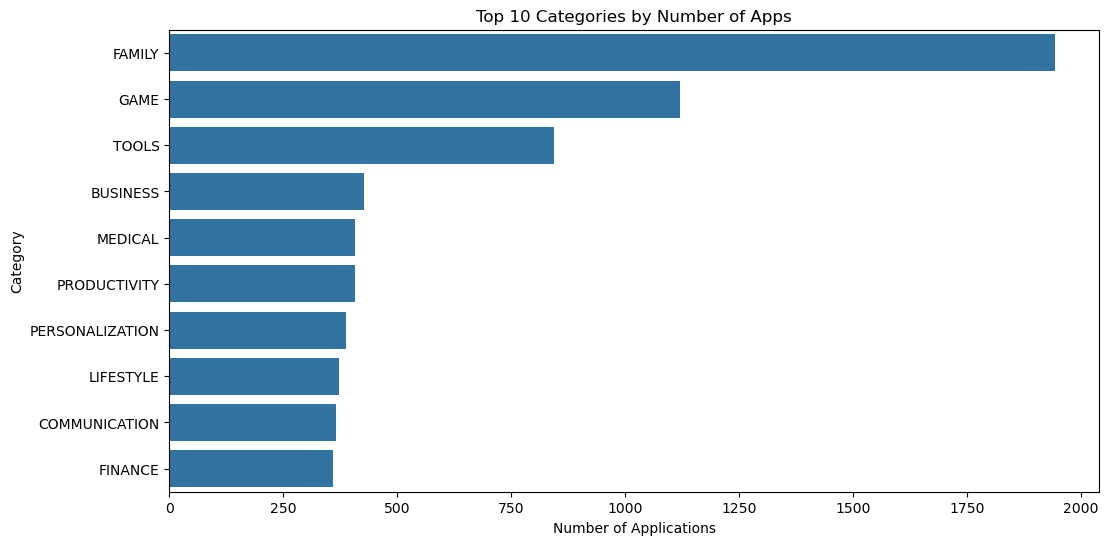

In [33]:
# Count applications in each category
category_counts = df["Category"].value_counts()

print(category_counts)

# Visualize the top 10 categories
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_counts.head(10).values,
    y=category_counts.head(10).index
)

plt.title("Top 10 Categories by Number of Apps")
plt.xlabel("Number of Applications")
plt.ylabel("Category")
plt.show()

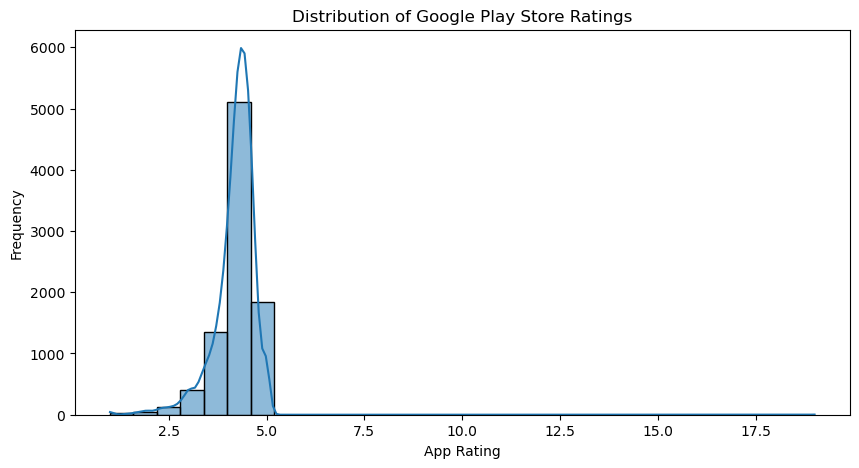

In [34]:
# Plot distribution of app ratings
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Rating",
    bins=30,
    kde=True
)

plt.title("Distribution of Google Play Store Ratings")
plt.xlabel("App Rating")
plt.ylabel("Frequency")
plt.show()

Type
Free    9593
Paid     765
Name: count, dtype: int64


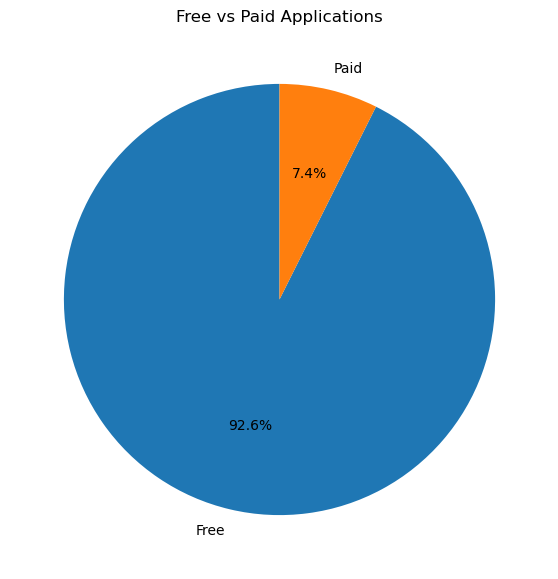

In [35]:
# Count free and paid applications
type_counts = df["Type"].value_counts()

print(type_counts)

# Create a pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    type_counts.values,
    labels=type_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Free vs Paid Applications")
plt.show()

Category
1.9                    19.000000
EVENTS                  4.435556
EDUCATION               4.375969
ART_AND_DESIGN          4.358065
BOOKS_AND_REFERENCE     4.347458
PERSONALIZATION         4.333871
PARENTING               4.300000
GAME                    4.281285
BEAUTY                  4.278571
HEALTH_AND_FITNESS      4.261450
SOCIAL                  4.254918
SHOPPING                4.251485
WEATHER                 4.244000
SPORTS                  4.225175
PRODUCTIVITY            4.201796
FAMILY                  4.191153
AUTO_AND_VEHICLES       4.190411
PHOTOGRAPHY             4.182895
MEDICAL                 4.182450
LIBRARIES_AND_DEMO      4.178462
HOUSE_AND_HOME          4.164706
FOOD_AND_DRINK          4.164151
COMICS                  4.155172
COMMUNICATION           4.151466
ENTERTAINMENT           4.136036
NEWS_AND_MAGAZINES      4.128505
FINANCE                 4.127445
BUSINESS                4.102593
LIFESTYLE               4.096066
TRAVEL_AND_LOCAL        4.094146
V

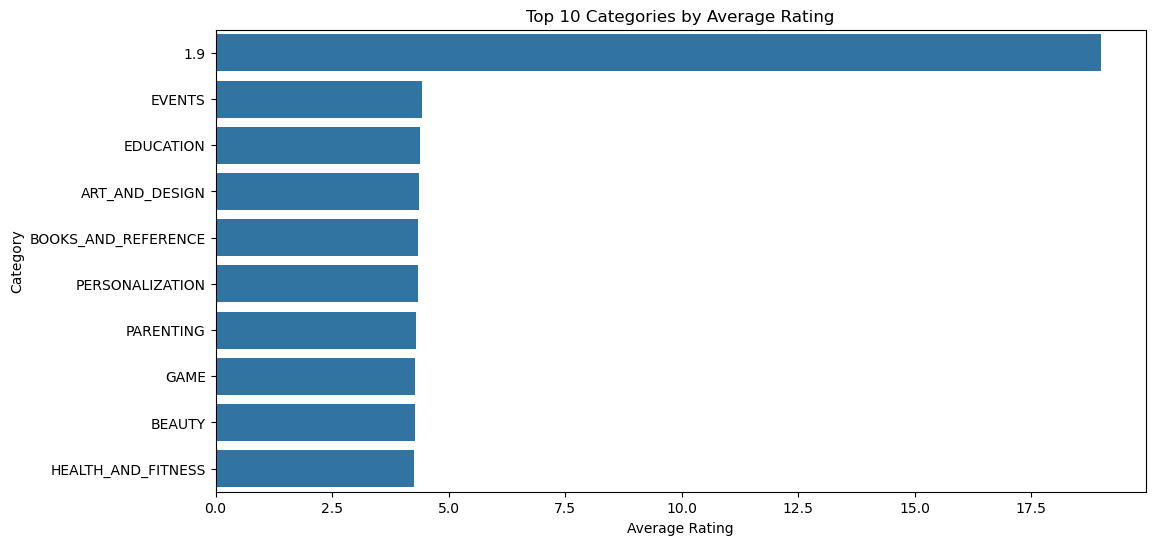

In [36]:
# Calculate average rating for each category
category_ratings = (
    df.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

print(category_ratings)

# Plot top 10 categories
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_ratings.head(10).values,
    y=category_ratings.head(10).index
)

plt.title("Top 10 Categories by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.show()

                               App       Category      Installs  Rating
308                       Hangouts  COMMUNICATION  1.000000e+09     4.0
3483                       YouTube  VIDEO_PLAYERS  1.000000e+09     4.3
412                          Gmail  COMMUNICATION  1.000000e+09     4.3
3549  Google Chrome: Fast & Secure  COMMUNICATION  1.000000e+09     4.3
1493                Subway Surfers           GAME  1.000000e+09     4.5
3035                  Google Drive   PRODUCTIVITY  1.000000e+09     4.4
2459                 Google Photos    PHOTOGRAPHY  1.000000e+09     4.5
755              Google Play Games  ENTERTAINMENT  1.000000e+09     4.3
2504                 Google Photos    PHOTOGRAPHY  1.000000e+09     4.5
375   Google Chrome: Fast & Secure  COMMUNICATION  1.000000e+09     4.3


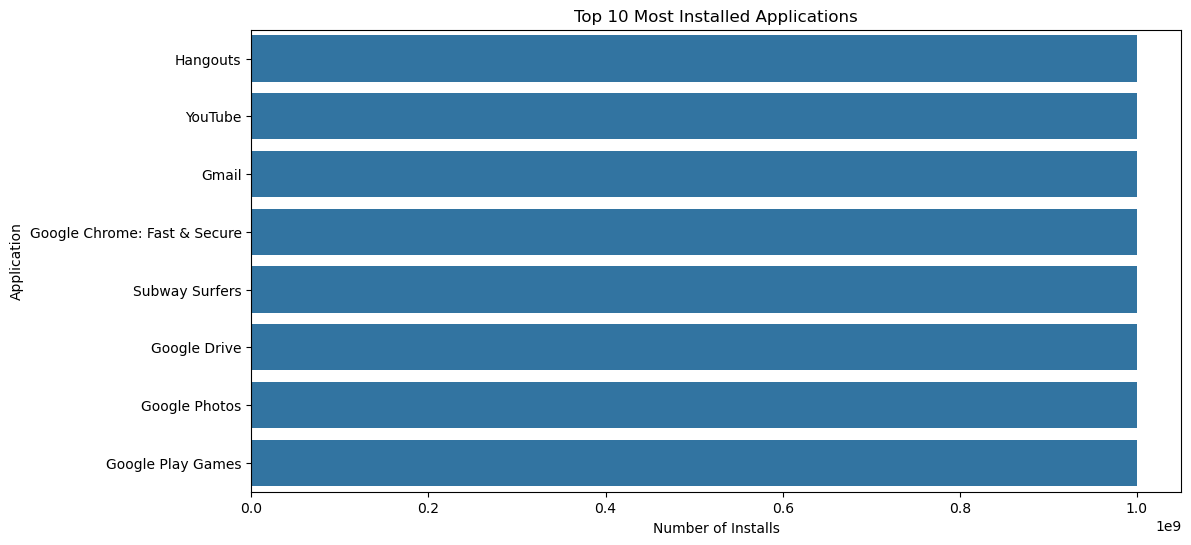

In [37]:
# Find top 10 applications by installs
top_apps = df.sort_values(
    by="Installs",
    ascending=False
).head(10)

print(top_apps[["App", "Category", "Installs", "Rating"]])

# Visualize top applications
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_apps,
    x="Installs",
    y="App"
)

plt.title("Top 10 Most Installed Applications")
plt.xlabel("Number of Installs")
plt.ylabel("Application")
plt.show()

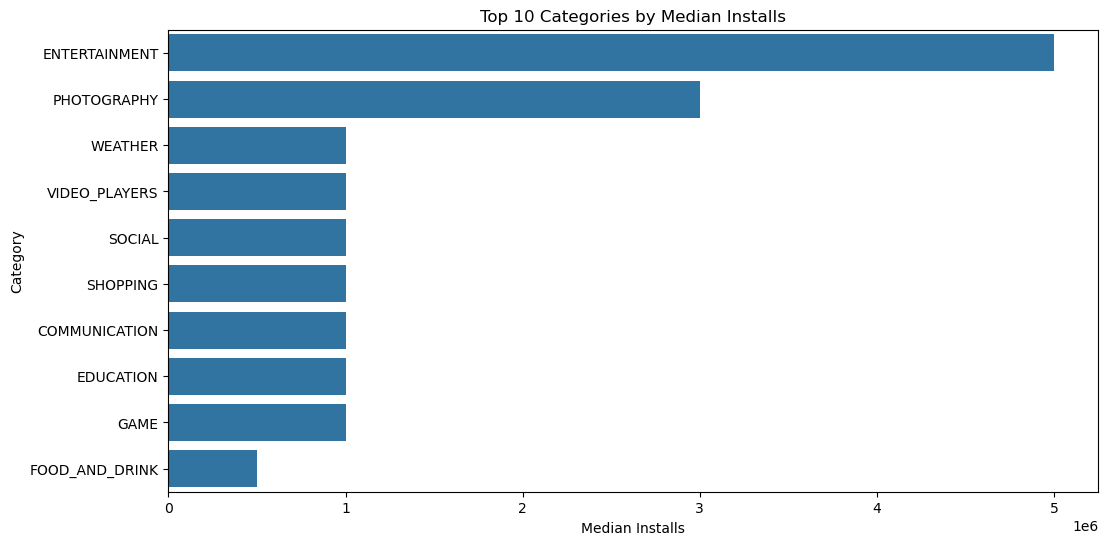

In [38]:
# Calculate median installs for each category
category_installs = (
    df.groupby("Category")["Installs"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_installs.values,
    y=category_installs.index
)

plt.title("Top 10 Categories by Median Installs")
plt.xlabel("Median Installs")
plt.ylabel("Category")
plt.show()

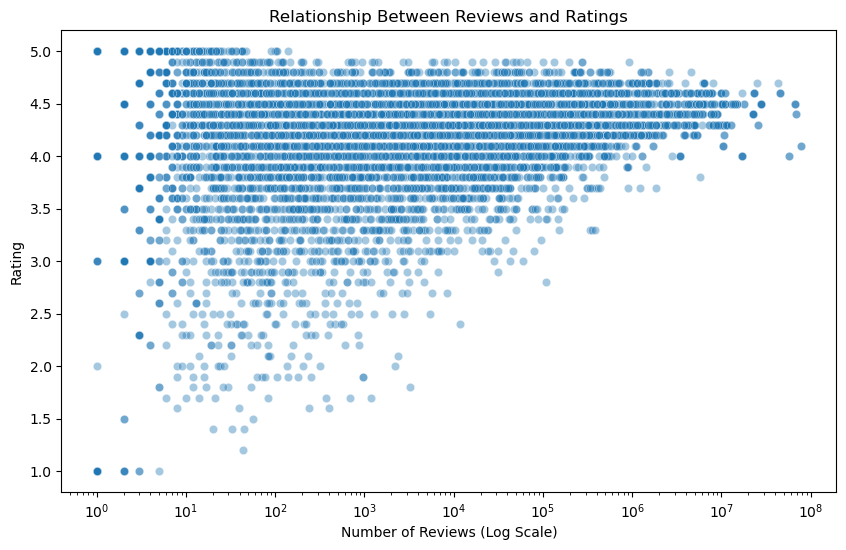

In [39]:
# Select records with valid rating and review counts
rating_reviews = df.dropna(
    subset=["Rating", "Reviews"]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rating_reviews,
    x="Reviews",
    y="Rating",
    alpha=0.4
)

plt.xscale("log")

plt.title("Relationship Between Reviews and Ratings")
plt.xlabel("Number of Reviews (Log Scale)")
plt.ylabel("Rating")
plt.show()

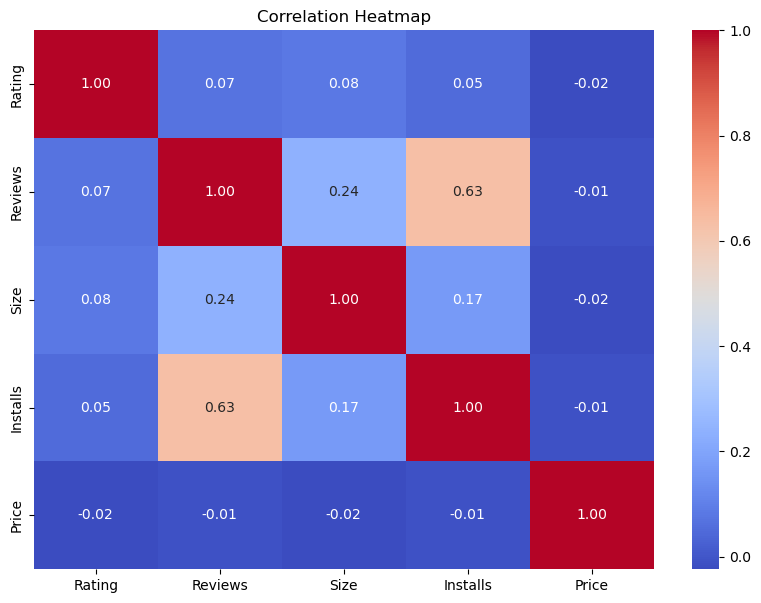

In [40]:
# Select numerical columns
numeric_data = df.select_dtypes(include=np.number)

# Calculate correlation
correlation = numeric_data.corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [41]:
# Generate a few useful business metrics

print("Total Applications:", len(df))

print("Unique Applications:", df["App"].nunique())

print("Average Rating:", round(df["Rating"].mean(), 2))

print("Total Installs:", df["Installs"].sum())

print("Free Applications:",
      (df["Type"] == "Free").sum())

print("Paid Applications:",
      (df["Type"] == "Paid").sum())

Total Applications: 10358
Unique Applications: 9660
Average Rating: 4.19
Total Installs: 146631914527.0
Free Applications: 9593
Paid Applications: 765


In [42]:
# Check minimum and maximum ratings

print("Minimum Rating:", df["Rating"].min())
print("Maximum Rating:", df["Rating"].max())

# Check ratings greater than 5
print("Ratings above 5:", (df["Rating"] > 5).sum())

# Check ratings below 1
print("Ratings below 1:", (df["Rating"] < 1).sum())

Minimum Rating: 1.0
Maximum Rating: 19.0
Ratings above 5: 1
Ratings below 1: 0


In [43]:
# Find applications having ratings greater than 5

invalid_ratings = df[df["Rating"] > 5]

# Display invalid records
invalid_ratings[["App", "Category", "Rating", "Reviews"]]

,App,Category,Rating,Reviews
9990,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.0,NaN


In [44]:
# Check review statistics

print(df["Reviews"].describe())

# Find applications having zero reviews
zero_reviews = df[df["Reviews"] == 0]

print("Applications with zero reviews:", len(zero_reviews))

count    1.035700e+04
mean     4.059046e+05
std      2.696778e+06
min      0.000000e+00
25%      3.200000e+01
50%      1.680000e+03
75%      4.641600e+04
max      7.815831e+07
Name: Reviews, dtype: float64
Applications with zero reviews: 593


In [45]:
# Check install statistics

print(df["Installs"].describe())

# Find top 10 applications by installs

df.nlargest(10, "Installs")[
    ["App", "Category", "Installs", "Rating"]
]

count    1.035700e+04
mean     1.415776e+07
std      8.023955e+07
min      0.000000e+00
25%      1.000000e+03
50%      1.000000e+05
75%      1.000000e+06
max      1.000000e+09
Name: Installs, dtype: float64


,App,Category,Installs,Rating
152,Google Play Books,BOOKS_AND_REFERENCE,1.000000e+09,3.9
302,Messenger – Text and Video Chat for Free,COMMUNICATION,1.000000e+09,4.0
303,WhatsApp Messenger,COMMUNICATION,1.000000e+09,4.4
305,Google Chrome: Fast & Secure,COMMUNICATION,1.000000e+09,4.3
307,Gmail,COMMUNICATION,1.000000e+09,4.3
308,Hangouts,COMMUNICATION,1.000000e+09,4.0
348,Messenger – Text and Video Chat for Free,COMMUNICATION,1.000000e+09,4.0
352,Hangouts,COMMUNICATION,1.000000e+09,4.0
357,Skype - free IM & video calls,COMMUNICATION,1.000000e+09,4.1
375,Google Chrome: Fast & Secure,COMMUNICATION,1.000000e+09,4.3


In [46]:
# Check duplicates after preprocessing

print("Exact duplicate rows:", df.duplicated().sum())

# Check missing values

print("Total missing values:", df.isnull().sum().sum())

Exact duplicate rows: 0
Total missing values: 2995


In [47]:
# Calculate numerical correlation

correlation = df.select_dtypes(
    include=np.number
).corr()

# Display correlation with Rating

print(
    correlation["Rating"].sort_values(
        ascending=False
    )
)

Rating      1.000000
Size        0.081969
Reviews     0.068732
Installs    0.050886
Price      -0.022355
Name: Rating, dtype: float64


In [48]:
# Calculate missing values and percentages

missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

missing_report = missing_report.sort_values(
    by="Missing_Count",
    ascending=False
)

missing_report

,Missing_Count,Missing_Percentage
Size,1527,14.74
Rating,1465,14.14
Reviews,1,0.01
Installs,1,0.01
Price,1,0.01
App,0,0.00
Category,0,0.00
Type,0,0.00
Content Rating,0,0.00
Genres,0,0.00


In [49]:
# Check rating boundaries

print("Minimum Rating:", df["Rating"].min())
print("Maximum Rating:", df["Rating"].max())

# Find ratings outside the valid range
invalid_ratings = df[
    (df["Rating"] < 1) | (df["Rating"] > 5)
]

print("Invalid rating records:", len(invalid_ratings))

invalid_ratings[["App", "Rating"]].head(20)

Minimum Rating: 1.0
Maximum Rating: 19.0
Invalid rating records: 1


,App,Rating
9990,Life Made WI-Fi Touchscreen Photo Frame,19.0


In [50]:
# Check numerical column data types

print(df[[
    "Rating",
    "Reviews",
    "Size",
    "Installs",
    "Price"
]].dtypes)

# Check negative values

print("Negative Reviews:", (df["Reviews"] < 0).sum())

print("Negative Installs:", (df["Installs"] < 0).sum())

print("Negative Prices:", (df["Price"] < 0).sum())

Rating      float64
Reviews     float64
Size        float64
Installs    float64
Price       float64
dtype: object
Negative Reviews: 0
Negative Installs: 0
Negative Prices: 0


In [51]:
# Display unique categories

print("Categories:", df["Category"].nunique())

print("\nTypes:")
print(df["Type"].value_counts())

print("\nContent Ratings:")
print(df["Content Rating"].value_counts())

print("\nGenres:")
print(df["Genres"].nunique())

Categories: 34

Types:
Type
Free    9593
Paid     765
Name: count, dtype: int64

Content Ratings:
Content Rating
Everyone           8383
Teen               1146
Mature 17+          447
Everyone 10+        377
Adults only 18+       3
Unrated               2
Name: count, dtype: int64

Genres:
120


In [52]:
# Display dataset information

df.info()

# Display dataset dimensions

print("\nDataset Shape:", df.shape)

# Check exact duplicates

print("Duplicate Rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10358 entries, 0 to 10357
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10358 non-null  object 
 1   Category        10358 non-null  object 
 2   Rating          8893 non-null   float64
 3   Reviews         10357 non-null  float64
 4   Size            8831 non-null   float64
 5   Installs        10357 non-null  float64
 6   Type            10358 non-null  object 
 7   Price           10357 non-null  float64
 8   Content Rating  10358 non-null  object 
 9   Genres          10358 non-null  object 
 10  Last Updated    10358 non-null  object 
 11  Current Ver     10358 non-null  object 
 12  Android Ver     10358 non-null  object 
dtypes: float64(5), object(8)
memory usage: 1.0+ MB

Dataset Shape: (10358, 13)
Duplicate Rows: 0


In [53]:
# Save missing-value report

missing_report.to_csv(
    "../data/missing_values_report.csv"
)

print("Validation report saved successfully!")

Validation report saved successfully!


In [54]:
# Import required libraries

import pandas as pd
import numpy as np

# Train-test splitting
from sklearn.model_selection import train_test_split

# Data preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


In [55]:
# Create an independent copy
model_data = df.copy()

# Keep only valid ratings between 1 and 5
model_data = model_data[
    model_data["Rating"].between(1, 5)
].copy()

# Reset index
model_data.reset_index(drop=True, inplace=True)

# Display dataset information
print("Original cleaned dataset:", df.shape)
print("Modeling dataset:", model_data.shape)

print("Missing target ratings:", model_data["Rating"].isnull().sum())

Original cleaned dataset: (10358, 13)
Modeling dataset: (8892, 13)
Missing target ratings: 0


In [56]:
# Select numerical features
numerical_features = [
    "Reviews",
    "Size",
    "Installs",
    "Price"
]

# Select categorical features
categorical_features = [
    "Category",
    "Type",
    "Content Rating",
    "Genres"
]

# Independent variables
X = model_data[
    numerical_features + categorical_features
].copy()

# Dependent variable
y = model_data["Rating"].copy()

# Display dimensions
print("Independent variables shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

Independent variables shape: (8892, 8)
Target variable shape: (8892,)

Features:
['Reviews', 'Size', 'Installs', 'Price', 'Category', 'Type', 'Content Rating', 'Genres']


In [57]:
# Convert numerical columns into numeric format
for col in numerical_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

# Replace infinite values with missing values
X[numerical_features] = X[numerical_features].replace(
    [np.inf, -np.inf],
    np.nan
)

# Ensure numerical values are non-negative
X[numerical_features] = X[numerical_features].clip(lower=0)

# Apply log transformation to reduce skewness
for col in numerical_features:
    X[col] = np.log1p(X[col])

print("Numerical transformation completed!")

X[numerical_features].head()

Numerical transformation completed!


,Reviews,Size,Installs,Price
0,5.075174,2.995732,9.210440,0.0
1,6.875232,2.708050,13.122365,0.0
2,11.379520,2.272126,15.424949,0.0
3,12.281389,3.258097,17.727534,0.0
4,6.875232,1.335001,11.512935,0.0


In [58]:
# Fill missing categorical values with Unknown

for col in categorical_features:
    X[col] = X[col].fillna("Unknown").astype(str)

# Check missing values
print("Missing values in X:", X.isnull().sum().sum())

# Display categorical features
X[categorical_features].head()

Missing values in X: 1468


,Category,Type,Content Rating,Genres
0,ART_AND_DESIGN,Free,Everyone,Art & Design
1,ART_AND_DESIGN,Free,Everyone,Art & Design;Pretend Play
2,ART_AND_DESIGN,Free,Everyone,Art & Design
3,ART_AND_DESIGN,Free,Teen,Art & Design
4,ART_AND_DESIGN,Free,Everyone,Art & Design;Creativity


In [59]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display dataset dimensions

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (7113, 8)
Testing features: (1779, 8)
Training target: (7113,)
Testing target: (1779,)


In [60]:
# Create numerical preprocessing pipeline

numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

print("Numerical pipeline created!")

Numerical pipeline created!


In [61]:
# Create categorical preprocessing pipeline

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

print("Categorical pipeline created!")

Categorical pipeline created!


In [62]:
# Combine numerical and categorical transformations

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Combined preprocessing pipeline created!")

Combined preprocessing pipeline created!


In [63]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

# Display shapes
print("Processed training data:", X_train_processed.shape)
print("Processed testing data:", X_test_processed.shape)

print("Preprocessing completed successfully!")

Processed training data: (7113, 155)
Processed testing data: (1779, 155)
Preprocessing completed successfully!


In [64]:
# Display processed dataset information

print("Training data type:", type(X_train_processed))

print("Training data shape:", X_train_processed.shape)

print("Testing data shape:", X_test_processed.shape)

print("Training target shape:", y_train.shape)

print("Testing target shape:", y_test.shape)

Training data type: <class 'scipy.sparse._csr.csr_matrix'>
Training data shape: (7113, 155)
Testing data shape: (1779, 155)
Training target shape: (7113,)
Testing target shape: (1779,)


In [65]:
# Save the dataset containing valid target ratings

model_data.to_csv(
    "../data/playstore_modeling_data.csv",
    index=False
)

print("Modeling dataset saved successfully!")

Modeling dataset saved successfully!


In [66]:
# Import machine learning algorithms

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Import evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pandas as pd
import numpy as np

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [67]:
# Create a dictionary containing all models

models = {
    "Baseline": DummyRegressor(strategy="mean"),

    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        max_depth=12,
        min_samples_leaf=5,
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        max_depth=20,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )
}

print("Total models created:", len(models))

Total models created: 4


In [68]:
# Create an empty dictionary to store trained models

trained_models = {}

# Train each machine learning model

for name, model in models.items():

    print(f"Training {name}...")

    # Fit model using training data
    model.fit(X_train_processed, y_train)

    # Store trained model
    trained_models[name] = model

    print(f"{name} training completed!")

print("\nAll models trained successfully!")

Training Baseline...
Baseline training completed!
Training Linear Regression...
Linear Regression training completed!
Training Decision Tree...
Decision Tree training completed!
Training Random Forest...
Random Forest training completed!

All models trained successfully!


In [69]:
# Create dictionary to store predictions

predictions = {}

# Generate predictions using each trained model

for name, model in trained_models.items():

    # Predict ratings using testing data
    y_pred = model.predict(X_test_processed)

    # Store predictions
    predictions[name] = y_pred

    print(f"{name} predictions completed!")

print("\nAll predictions generated successfully!")

Baseline predictions completed!
Linear Regression predictions completed!
Decision Tree predictions completed!
Random Forest predictions completed!

All predictions generated successfully!


In [70]:
# Create empty list to store evaluation results

results = []

# Evaluate every trained model

for name, y_pred in predictions.items():

    # Calculate Mean Absolute Error
    mae = mean_absolute_error(y_test, y_pred)

    # Calculate Mean Squared Error
    mse = mean_squared_error(y_test, y_pred)

    # Calculate Root Mean Squared Error
    rmse = np.sqrt(mse)

    # Calculate R2 Score
    r2 = r2_score(y_test, y_pred)

    # Store results
    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Convert results into DataFrame

results_df = pd.DataFrame(results)

print("Model evaluation completed!")

results_df

Model evaluation completed!


,Model,MAE,MSE,RMSE,R2 Score
0,Baseline,0.363759,0.263697,0.513514,-0.002334
1,Linear Regression,0.332364,0.231556,0.481203,0.119837
2,Decision Tree,0.339806,0.257356,0.507303,0.021767
3,Random Forest,0.317849,0.229982,0.479564,0.125819


In [71]:
# Sort models based on R2 Score

results_sorted = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

# Display model comparison

results_sorted

,Model,MAE,MSE,RMSE,R2 Score
3,Random Forest,0.317849,0.229982,0.479564,0.125819
1,Linear Regression,0.332364,0.231556,0.481203,0.119837
2,Decision Tree,0.339806,0.257356,0.507303,0.021767
0,Baseline,0.363759,0.263697,0.513514,-0.002334


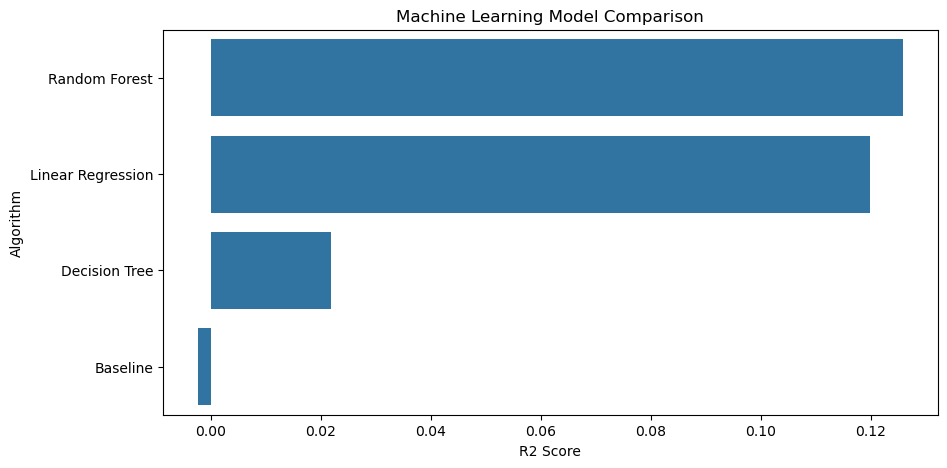

In [72]:
# Plot R2 Score comparison

plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_sorted,
    x="R2 Score",
    y="Model"
)

plt.title("Machine Learning Model Comparison")
plt.xlabel("R2 Score")
plt.ylabel("Algorithm")
plt.show()

In [73]:
# Select the best model based on R2 Score

best_model_name = results_sorted.iloc[0]["Model"]

# Get predictions from the best model
best_predictions = predictions[best_model_name]

# Create comparison DataFrame
comparison = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": best_predictions
})

# Display first 20 predictions
print("Best Model:", best_model_name)

comparison.head(20)

Best Model: Random Forest


,Actual Rating,Predicted Rating
0,4.6,4.486551
1,4.6,4.530762
2,4.3,4.043593
3,4.6,4.341827
4,4.1,4.195524
5,4.5,4.085420
6,4.5,4.455769
7,4.7,4.418539
8,4.6,4.503470
9,3.1,3.866851


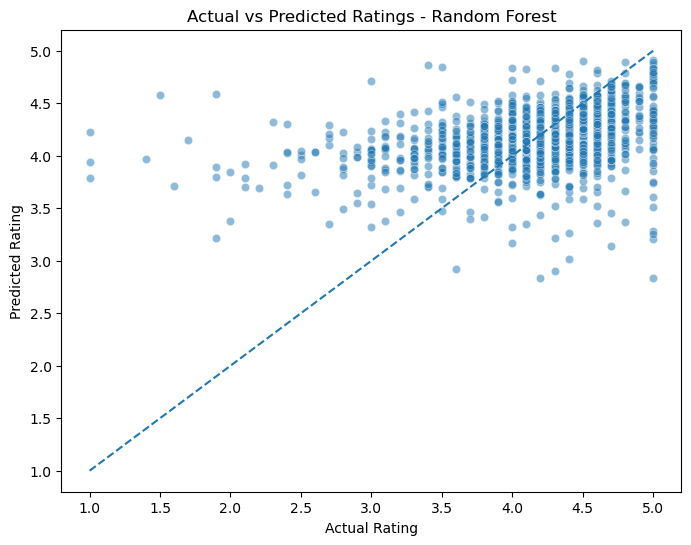

In [74]:
# Plot actual ratings against predicted ratings

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.5
)

# Draw ideal prediction line
plt.plot(
    [1, 5],
    [1, 5],
    linestyle="--"
)

plt.title(f"Actual vs Predicted Ratings - {best_model_name}")
plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.show()

In [75]:
# Get feature names after preprocessing

feature_names = preprocessor.get_feature_names_out()

# Select the best model
best_model = trained_models[best_model_name]

# Extract feature importance for tree-based models
if hasattr(best_model, "feature_importances_"):

    importance_values = best_model.feature_importances_

# Extract coefficients for Linear Regression
elif hasattr(best_model, "coef_"):

    importance_values = np.abs(best_model.coef_)

else:

    importance_values = None


# Display important features

if importance_values is not None:

    feature_importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance_values
    })

    feature_importance = feature_importance.sort_values(
        by="Importance",
        ascending=False
    )

    print("Top 15 important features:")

    display(feature_importance.head(15))

else:

    print("Feature importance is unavailable for this model.")

Top 15 important features:


,Feature,Importance
0,num__Reviews,0.359921
1,num__Size,0.238035
2,num__Installs,0.130061
3,num__Price,0.026464
15,cat__Category_FAMILY,0.014947
40,cat__Content Rating_Everyone,0.010355
33,cat__Category_TOOLS,0.010091
93,cat__Genres_Entertainment,0.009889
80,cat__Genres_Education,0.009175
145,cat__Genres_Tools,0.009135


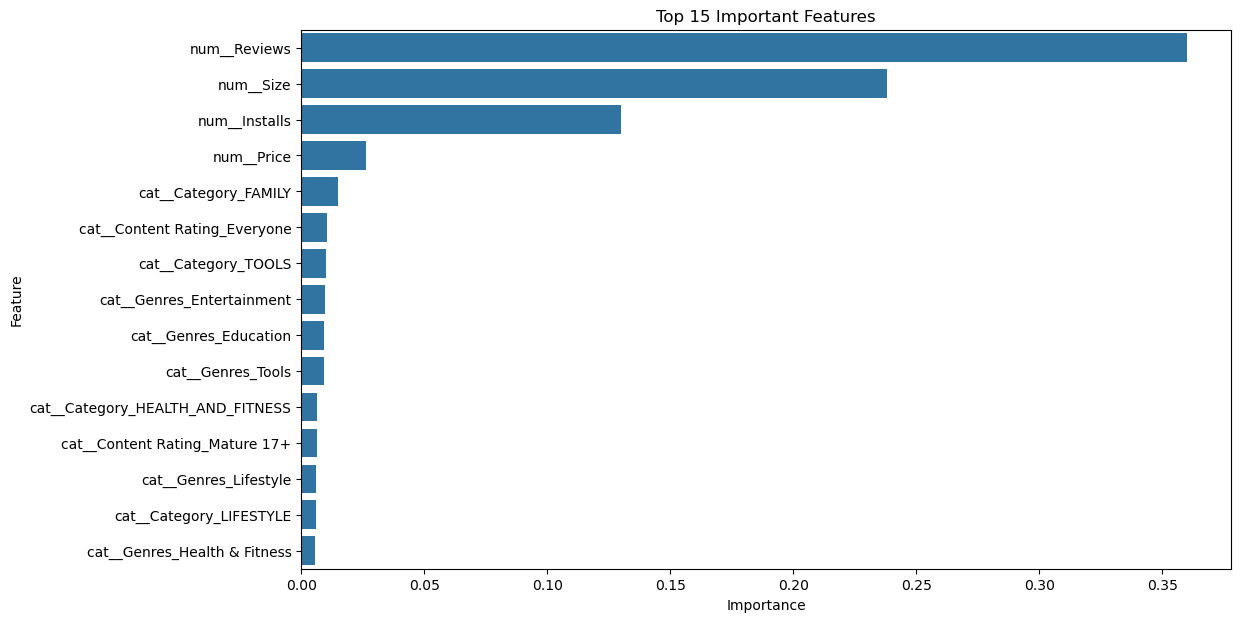

In [76]:
# Plot top 15 important features

if importance_values is not None:

    top_features = feature_importance.head(15)

    plt.figure(figsize=(12, 7))

    sns.barplot(
        data=top_features,
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")
    plt.xlabel("Importance")
    plt.ylabel("Feature")

    plt.show()

In [77]:
# Save model comparison results

results_sorted.to_csv(
    "../data/model_comparison_results.csv",
    index=False
)

# Save actual and predicted ratings

comparison.to_csv(
    "../data/prediction_results.csv",
    index=False
)

print("Model comparison saved successfully!")
print("Prediction results saved successfully!")

Model comparison saved successfully!
Prediction results saved successfully!


In [78]:
# Import joblib for saving machine learning models

import joblib

# Save preprocessing and trained models together

model_bundle = {
    "preprocessor": preprocessor,
    "models": trained_models,
    "feature_columns": X.columns.tolist()
}

joblib.dump(
    model_bundle,
    "../data/playstore_ml_models.pkl"
)

print("All trained models saved successfully!")

All trained models saved successfully!


In [79]:
# Display model performance in descending order

results_sorted = results_df.sort_values(
    by="R2 Score",
    ascending=False
)

display(results_sorted)

,Model,MAE,MSE,RMSE,R2 Score
3,Random Forest,0.317849,0.229982,0.479564,0.125819
1,Linear Regression,0.332364,0.231556,0.481203,0.119837
2,Decision Tree,0.339806,0.257356,0.507303,0.021767
0,Baseline,0.363759,0.263697,0.513514,-0.002334


In [80]:
# Compare training and testing performance

overfitting_results = []

for name, model in trained_models.items():

    # Predict on training data
    train_pred = model.predict(X_train_processed)

    # Predict on testing data
    test_pred = model.predict(X_test_processed)

    # Calculate R2 scores
    train_r2 = r2_score(y_train, train_pred)
    test_r2 = r2_score(y_test, test_pred)

    overfitting_results.append({
        "Model": name,
        "Training R2": train_r2,
        "Testing R2": test_r2,
        "Difference": train_r2 - test_r2
    })

overfitting_df = pd.DataFrame(overfitting_results)

display(overfitting_df.sort_values(
    by="Testing R2",
    ascending=False
))

,Model,Training R2,Testing R2,Difference
3,Random Forest,0.644140,0.125819,0.518320
1,Linear Regression,0.175187,0.119837,0.055350
2,Decision Tree,0.351705,0.021767,0.329938
0,Baseline,0.000000,-0.002334,0.002334


In [81]:
# Import hyperparameter tuning tools
from sklearn.model_selection import RandomizedSearchCV

# Import Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor

# Import evaluation metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [82]:
# Define different parameter combinations

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, 20, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 4, 8],
    "max_features": [0.5, 0.7, 1.0]
}

In [83]:
# Create Random Forest model

rf_model = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

# Initialize Randomized Search

random_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=param_grid,
    n_iter=20,
    cv=3,
    scoring="r2",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Train using different hyperparameter combinations

random_search.fit(X_train_processed, y_train)

# Display best parameters

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross Validation R2:")
print(random_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 0.5, 'max_depth': 15}

Best Cross Validation R2:
0.1654782575136299


In [84]:
# Get the best model

best_rf_model = random_search.best_estimator_

# Make predictions

tuned_predictions = best_rf_model.predict(X_test_processed)

# Calculate evaluation metrics

tuned_r2 = r2_score(y_test, tuned_predictions)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)

# Display results

print("Optimized Random Forest Results")

print("R2 Score:", round(tuned_r2, 4))
print("MAE:", round(tuned_mae, 4))
print("RMSE:", round(tuned_rmse, 4))

Optimized Random Forest Results
R2 Score: 0.145
MAE: 0.3242
RMSE: 0.4743


In [85]:
# Compare model performance

comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Optimized Random Forest",
        "Linear Regression"
    ],
    "R2 Score": [
        0.125819,
        tuned_r2,
        r2_score(y_test, trained_models["Linear Regression"].predict(X_test_processed))
    ]
})

display(
    comparison.sort_values(
        by="R2 Score",
        ascending=False
    )
)

,Model,R2 Score
1,Optimized Random Forest,0.145001
0,Original Random Forest,0.125819
2,Linear Regression,0.119837


In [86]:
# Save optimized Random Forest model

joblib.dump(
    best_rf_model,
    "../data/best_playstore_model.pkl"
)

print("Optimized model saved successfully!")

Optimized model saved successfully!


In [87]:
# Extract feature importance from the optimized Random Forest model

feature_importance = best_rf_model.feature_importances_

# Get feature names from the preprocessing pipeline

feature_names = preprocessor.get_feature_names_out()

# Create a DataFrame containing features and their importance

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

# Sort features by importance

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 important features

display(importance_df.head(15))

,Feature,Importance
0,num__Reviews,0.404199
2,num__Installs,0.207901
1,num__Size,0.151676
3,num__Price,0.029926
33,cat__Category_TOOLS,0.013364
15,cat__Category_FAMILY,0.013242
80,cat__Genres_Education,0.013184
145,cat__Genres_Tools,0.011412
40,cat__Content Rating_Everyone,0.009774
93,cat__Genres_Entertainment,0.008348


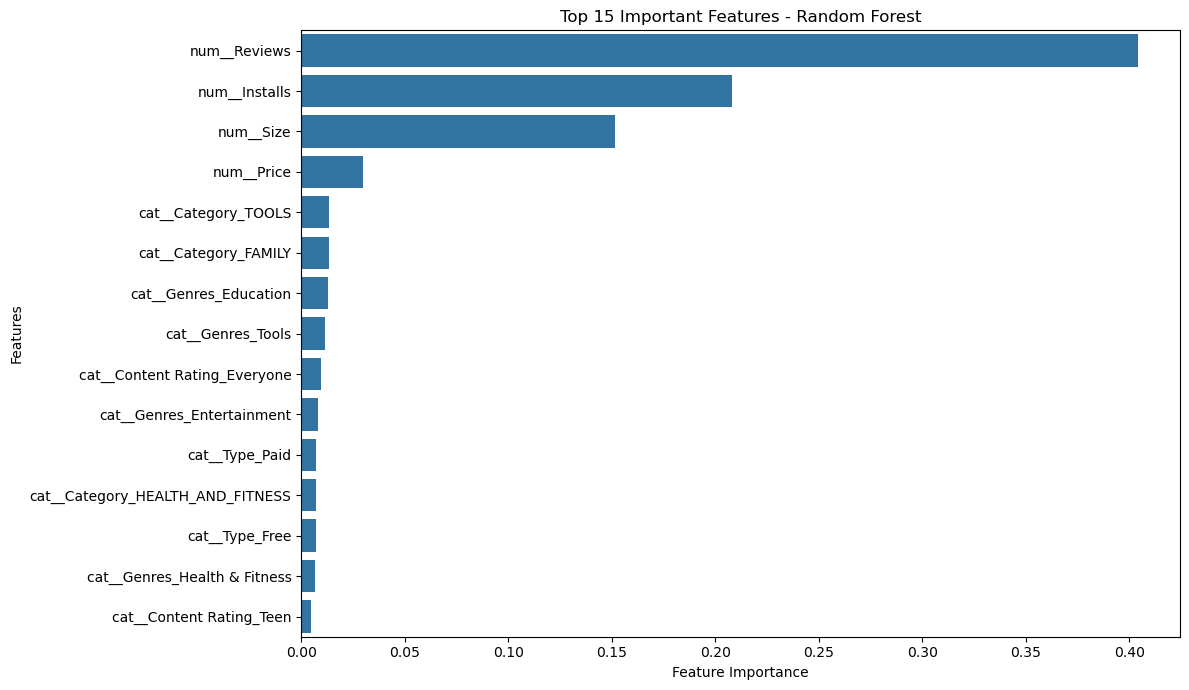

In [88]:
# Import visualization library

import matplotlib.pyplot as plt
import seaborn as sns

# Select top 15 features

top_features = importance_df.head(15)

# Create figure

plt.figure(figsize=(12, 7))

# Create horizontal bar chart

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

# Add chart title and labels

plt.title("Top 15 Important Features - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

# Adjust layout

plt.tight_layout()

# Display chart

plt.show()

In [89]:
# Calculate percentage contribution of each feature's importance score

importance_df["Importance_Percentage"] = (
    importance_df["Importance"] * 100
)

# Display top 15 features with percentages

display(
    importance_df[
        ["Feature", "Importance", "Importance_Percentage"]
    ].head(15)
)

,Feature,Importance,Importance_Percentage
0,num__Reviews,0.404199,40.419854
2,num__Installs,0.207901,20.790112
1,num__Size,0.151676,15.167570
3,num__Price,0.029926,2.992633
33,cat__Category_TOOLS,0.013364,1.336364
15,cat__Category_FAMILY,0.013242,1.324223
80,cat__Genres_Education,0.013184,1.318396
145,cat__Genres_Tools,0.011412,1.141175
40,cat__Content Rating_Everyone,0.009774,0.977427
93,cat__Genres_Entertainment,0.008348,0.834753


In [90]:
# Get the most important feature

most_important_feature = importance_df.iloc[0]

print("Most Important Feature:", most_important_feature["Feature"])

print(
    "Importance Percentage:",
    round(most_important_feature["Importance_Percentage"], 2),
    "%"
)

Most Important Feature: num__Reviews
Importance Percentage: 40.42 %


In [91]:
# Save feature importance results as CSV

importance_df.to_csv(
    "../data/feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!


In [92]:
# Generate predictions on training data

train_predictions = best_rf_model.predict(X_train_processed)

# Generate predictions on testing data

test_predictions = best_rf_model.predict(X_test_processed)

# Calculate training R2 score

train_r2 = r2_score(y_train, train_predictions)

# Calculate testing R2 score

test_r2 = r2_score(y_test, test_predictions)

# Display results

print("Training R2 Score:", round(train_r2, 4))
print("Testing R2 Score:", round(test_r2, 4))

print("Performance Difference:", round(train_r2 - test_r2, 4))

Training R2 Score: 0.3139
Testing R2 Score: 0.145
Performance Difference: 0.1689


In [93]:
# Import cross-validation function

from sklearn.model_selection import cross_val_score

# Perform 5-fold cross-validation on training data

cv_scores = cross_val_score(
    best_rf_model,
    X_train_processed,
    y_train,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

# Display individual scores

print("Cross Validation Scores:", cv_scores)

# Calculate average score

print("Average CV Score:", round(cv_scores.mean(), 4))

# Calculate standard deviation

print("CV Standard Deviation:", round(cv_scores.std(), 4))

Cross Validation Scores: [0.14144512 0.17924609 0.20291229 0.18819467 0.10862832]
Average CV Score: 0.1641
CV Standard Deviation: 0.0344


In [94]:
# Calculate residuals

residuals = y_test - test_predictions

# Create residual DataFrame

residual_df = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": test_predictions,
    "Residual": residuals
})

# Display first 10 predictions

display(residual_df.head(10))

,Actual Rating,Predicted Rating,Residual
5333,4.6,4.500655,0.099345
3405,4.6,4.418962,0.181038
5164,4.3,4.028397,0.271603
1659,4.6,4.395585,0.204415
1400,4.1,4.166252,-0.066252
8888,4.5,4.120430,0.379570
3441,4.5,4.475111,0.024889
2751,4.7,4.376922,0.323078
6270,4.6,4.462889,0.137111
6521,3.1,3.931490,-0.831490


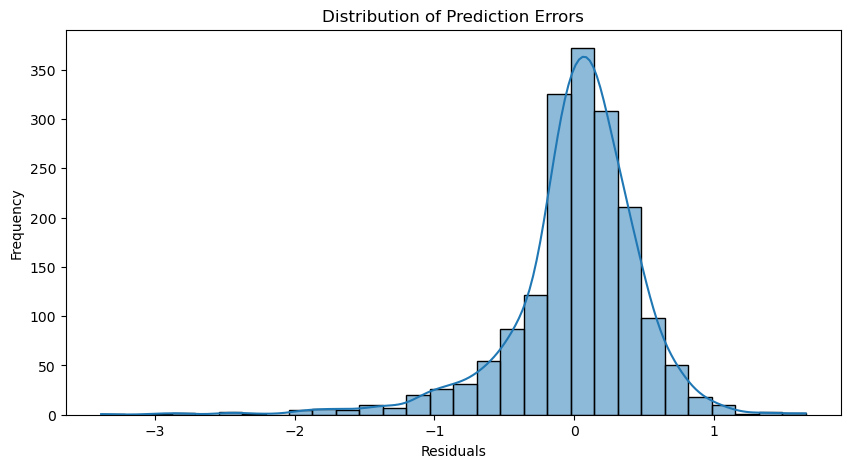

In [95]:
# Create residual distribution plot

plt.figure(figsize=(10, 5))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.show()

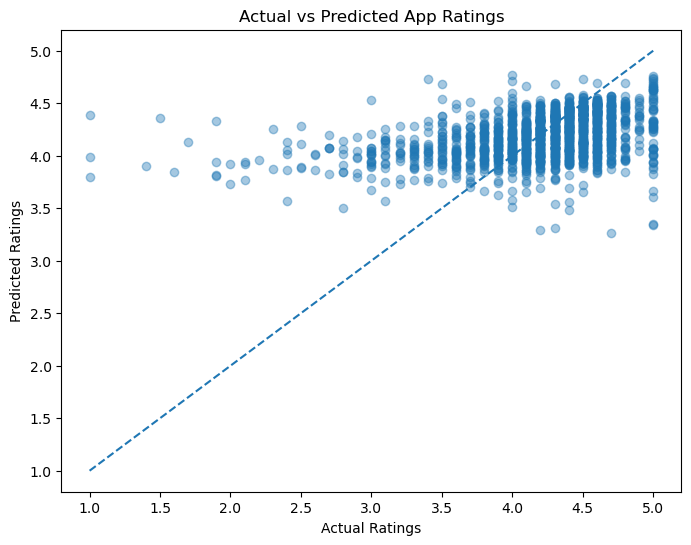

In [96]:
# Compare actual and predicted ratings

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    test_predictions,
    alpha=0.4
)

# Draw ideal prediction line

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.title("Actual vs Predicted App Ratings")
plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")

plt.show()

In [97]:
# Calculate final evaluation metrics

final_mae = mean_absolute_error(y_test, test_predictions)

final_rmse = np.sqrt(
    mean_squared_error(y_test, test_predictions)
)

final_r2 = r2_score(y_test, test_predictions)

# Create evaluation report

final_report = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2 Score", "Average CV R2"],
    "Value": [
        final_mae,
        final_rmse,
        final_r2,
        cv_scores.mean()
    ]
})

display(final_report)

# Save evaluation report

final_report.to_csv(
    "../data/final_model_evaluation.csv",
    index=False
)

print("Final evaluation report saved successfully!")

,Metric,Value
0,MAE,0.324192
1,RMSE,0.474274
2,R2 Score,0.145001
3,Average CV R2,0.164085


Final evaluation report saved successfully!


In [98]:
# Create a bundle containing preprocessing and trained model

model_bundle = {
    "preprocessor": preprocessor,
    "model": best_rf_model,
    "feature_columns": X.columns.tolist()
}

print("Model bundle created successfully!")

Model bundle created successfully!


In [99]:
# Save the model bundle using joblib

joblib.dump(
    model_bundle,
    "../data/playstore_final_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [100]:
# Load the saved model bundle

loaded_bundle = joblib.load(
    "../data/playstore_final_model.pkl"
)

# Extract preprocessing pipeline and model

loaded_preprocessor = loaded_bundle["preprocessor"]

loaded_model = loaded_bundle["model"]

print("Model loaded successfully!")

Model loaded successfully!


In [101]:
# Select one application from testing data

sample_app = X_test.iloc[[0]]

# Display application details

display(sample_app)

,Reviews,Size,Installs,Price,Category,Type,Content Rating,Genres
5333,9.008958,1.435085,11.512935,0.0,SHOPPING,Free,Everyone,Shopping


In [102]:
# Transform raw application data

sample_processed = loaded_preprocessor.transform(sample_app)

# Predict application rating

predicted_rating = loaded_model.predict(sample_processed)

# Display prediction

print(
    "Predicted Application Rating:",
    round(predicted_rating[0], 2)
)

Predicted Application Rating: 4.5


In [103]:
# Get actual rating from testing dataset

actual_rating = y_test.iloc[0]

# Display comparison

print("Actual Rating:", round(actual_rating, 2))

print("Predicted Rating:", round(predicted_rating[0], 2))

print(
    "Prediction Error:",
    round(abs(actual_rating - predicted_rating[0]), 2)
)

Actual Rating: 4.6
Predicted Rating: 4.5
Prediction Error: 0.1
